# Studi Kasus 6: Interaksi Manusia dan Komputer (IMK) serta Visualisasi Data (UCD & Anti-Chartjunk)

**Topik Webinar:** *Interaksi Manusia dan Komputer (IMK) serta Visualisasi Data*  
**Fokus Implementasi:** Penerapan pendekatan **User-Centered Design (UCD)** untuk meminimalkan beban kognitif (*cognitive load*) pengguna, penghapusan elemen dekoratif berlebihan (**[Chartjunk — Edward Tufte](https://www.edwardtufte.com/book/the-visual-display-of-quantitative-information/)**) demi memaksimalkan *Data-Ink Ratio*, serta implementasi arsitektur dasbor interaktif berdasarkan **[Ben Shneiderman's Visual Information Seeking Mantra](https://hci.stanford.edu/courses/cs448b/papers/shneiderman96eyes.pdf)**:
> *"Overview first, zoom and filter, then details-on-demand."*

### Skenario Eksperimen Usability & Dasbor Eksekutif (1.200 Sesi Evaluasi)
Dataset `dataset 06 imk ucd dashboard kinerja daerah.csv` merekam pengujian *A/B Usability Testing* antara antarmuka dasbor lama (`UI_Lama_Penuh_Chartjunk`) melawan antarmuka baru berbasis UCD (`UI_Baru_UCD_Clean`) pada 8 provinsi di Indonesia (termasuk **Bengkulu**):
1. **Evaluasi Statistik Beban Kognitif (NASA-TLX) & System Usability Scale (SUS):** Menguji signifikansi penurunan waktu pemahaman informasi (*Time-to-Insight*) dan tingkat kesalahan keputusan (*Decision Error Rate*).
2. **Transformasi Visual Anti-Chartjunk:** Mendemonstrasikan secara langsung perbedaan grafik yang terdistorsi oleh *chartjunk* (warna pelangi tak bermakna, *hatching* berisik, *gridline* rapat, label bertumpuk) melawan desain bersih berstandar **Tufte Data-Ink Maximization**.
3. **Implementasi Dasbor 3-Lapis (Overview, Filter, Details-on-Demand):** Menyajikan ringkasan makro KPI, penyaringan spesifik provinsi/layanan, dan tabel *drill-down* anomali.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

plt.rcParams['figure.dpi'] = 120
sns.set_theme(style="whitegrid")

DATASET_FILENAME = "dataset 06 imk ucd dashboard kinerja daerah.csv"
CANDIDATE_PATHS = [
    DATASET_FILENAME,
    f"/content/{DATASET_FILENAME}",
    f"/content/drive/MyDrive/Tugas Machine Learning Webinar/{DATASET_FILENAME}"
]

def load_or_generate_imk_data():
    for path in CANDIDATE_PATHS:
        if os.path.exists(path):
            print(f"[INFO] Memuat dataset evaluasi IMK & Visualisasi Data dari: {path}")
            return pd.read_csv(path)
    print("[INFO] Membangun ulang dataset deterministik evaluasi UCD & Dasbor...")
    np.random.seed(606)
    n = 1200
    provinsi_list = ["Bengkulu", "DKI Jakarta", "Jawa Barat", "Sumatera Barat", "Sumatera Selatan", "DI Yogyakarta", "Jawa Timur", "Kalimantan Timur"]
    kuartal_list = ["2025-Q1", "2025-Q2", "2025-Q3", "2025-Q4", "2026-Q1", "2026-Q2", "2026-Q3"]
    layanan_list = ["Perizinan_UMKM_Digital", "Layanan_Kesehatan_Terpadu", "Peringatan_Dini_Bencana", "Transparansi_Anggaran_Publik"]
    ui_design_version = np.random.choice(["UI_Lama_Penuh_Chartjunk", "UI_Baru_UCD_Clean"], size=n, p=[0.50, 0.50])
    prov = np.random.choice(provinsi_list, size=n)
    kuartal = np.random.choice(kuartal_list, size=n)
    layanan = np.random.choice(layanan_list, size=n)
    is_ucd = (ui_design_version == "UI_Baru_UCD_Clean")
    nasa_tlx = np.where(is_ucd, np.clip(np.random.normal(31.5, 7.5, size=n), 12.0, 65.0), np.clip(np.random.normal(68.4, 9.8, size=n), 38.0, 96.0)).round(1)
    sus_score = np.where(is_ucd, np.clip(np.random.normal(84.2, 6.2, size=n), 60.0, 99.0), np.clip(np.random.normal(51.8, 9.5, size=n), 25.0, 78.0)).round(1)
    tti_sec = np.where(is_ucd, np.clip(np.random.lognormal(mean=2.85, sigma=0.28, size=n), 6.0, 55.0), np.clip(np.random.lognormal(mean=3.92, sigma=0.35, size=n), 18.0, 160.0)).round(1)
    err_pct = np.where(is_ucd, np.clip(np.random.exponential(scale=3.2, size=n), 0.0, 18.0), np.clip(np.random.normal(16.5, 5.2, size=n), 2.0, 38.0)).round(2)
    sla_pct = np.clip(92.0 - 0.18 * nasa_tlx + np.random.normal(0, 3.5, size=n), 55.0, 99.8).round(2)
    citizens = np.random.poisson(lam=1450, size=n) + np.where(prov == "DKI Jakarta", 950, np.where(prov == "Bengkulu", 320, 500))
    df_out = pd.DataFrame({
        "session_id": [f"UCD-SES-{60000+i}" for i in range(n)], "provinsi": prov, "kuartal": kuartal,
        "kategori_layanan": layanan, "ui_design_version": ui_design_version, "sus_usability_score": sus_score,
        "nasa_tlx_cognitive_load": nasa_tlx, "time_to_insight_sec": tti_sec, "decision_error_pct": err_pct,
        "sla_completion_rate_pct": sla_pct, "active_citizens_served": citizens
    })
    df_out.to_csv(DATASET_FILENAME, index=False)
    return df_out

df_imk = load_or_generate_imk_data()
print(f"Total Sesi Pengujian Usability & Kinerja Dasbor: {len(df_imk)} baris")

grp_junk = df_imk[df_imk["ui_design_version"] == "UI_Lama_Penuh_Chartjunk"]
grp_ucd = df_imk[df_imk["ui_design_version"] == "UI_Baru_UCD_Clean"]

t_stat_tti, p_val_tti = stats.ttest_ind(grp_junk["time_to_insight_sec"], grp_ucd["time_to_insight_sec"], equal_var=False)
cohens_d_tlx = (grp_junk["nasa_tlx_cognitive_load"].mean() - grp_ucd["nasa_tlx_cognitive_load"].mean()) / np.sqrt(
    0.5 * (grp_junk["nasa_tlx_cognitive_load"].var() + grp_ucd["nasa_tlx_cognitive_load"].var())
)

summary_ab = df_imk.groupby("ui_design_version").agg(
    SUS_Usability_Score=("sus_usability_score", "mean"),
    NASA_TLX_Beban_Kognitif=("nasa_tlx_cognitive_load", "mean"),
    Waktu_Paham_Detik=("time_to_insight_sec", "mean"),
    Tingkat_Salah_Keputusan_Pct=("decision_error_pct", "mean"),
    SLA_Tercapai_Pct=("sla_completion_rate_pct", "mean")
).round(2)

print("\n=== HASIL EKSPERIMEN A/B USABILITY: DESAIN CHARTJUNK VS USER-CENTERED DESIGN (UCD) ===")
print(summary_ab.to_string())
print(f"\\nUji Statistik Time-to-Insight : t-stat = {t_stat_tti:.2f}, p-value = {p_val_tti:.2e} (Sangat Signifikan)")
print(f"Ukuran Efek Penurunan Beban Kognitif (Cohen's d NASA-TLX) = {cohens_d_tlx:.2f} (Efek Sangat Besar)")

[INFO] Memuat dataset evaluasi IMK & Visualisasi Data dari: dataset 06 imk ucd dashboard kinerja daerah.csv
Total Sesi Pengujian Usability & Kinerja Dasbor: 1200 baris

=== HASIL EKSPERIMEN A/B USABILITY: DESAIN CHARTJUNK VS USER-CENTERED DESIGN (UCD) ===
                         SUS_Usability_Score  NASA_TLX_Beban_Kognitif  Waktu_Paham_Detik  Tingkat_Salah_Keputusan_Pct  SLA_Tercapai_Pct
ui_design_version                                                                                                                      
UI_Baru_UCD_Clean                      84.24                    32.07              18.04                         3.21             85.90
UI_Lama_Penuh_Chartjunk                51.93                    68.75              52.92                        16.68             79.64
\nUji Statistik Time-to-Insight : t-stat = 44.07, p-value = 2.62e-204 (Sangat Signifikan)
Ukuran Efek Penurunan Beban Kognitif (Cohen's d NASA-TLX) = 4.22 (Efek Sangat Besar)


### Tahap 1: Transformasi Visual — Dari *Chartjunk* Menuju Desain Bersih Berstandar Edward Tufte
Di bawah ini kita membandingkan cara penyajian metrik yang sama (**Tingkat Pencapaian SLA Layanan Publik per Provinsi**):
- **Panel Kiri (Buruk / Penuh *Chartjunk*):** Menggunakan warna pelangi acak yang membebani memori visual, tekstur arsiran (*hatching*) yang memicu efek *Moiré*, garis *grid* berlapis yang mengganggu, batas bingkai tebal, dan tanpa pengurutan logis.
- **Panel Kanan (Baik / Standar UCD & Tufte):** Diurutkan secara bermakna (*ranked horizontal bar*), menghapus dekorasi tanpa informasi (*despined*), menggunakan penekanan warna semantik (*semantic highlighting* khusus untuk menyorot **Bengkulu** vs. rata-rata nasional), dan mencantumkan label angka secara langsung (*direct data labeling*).

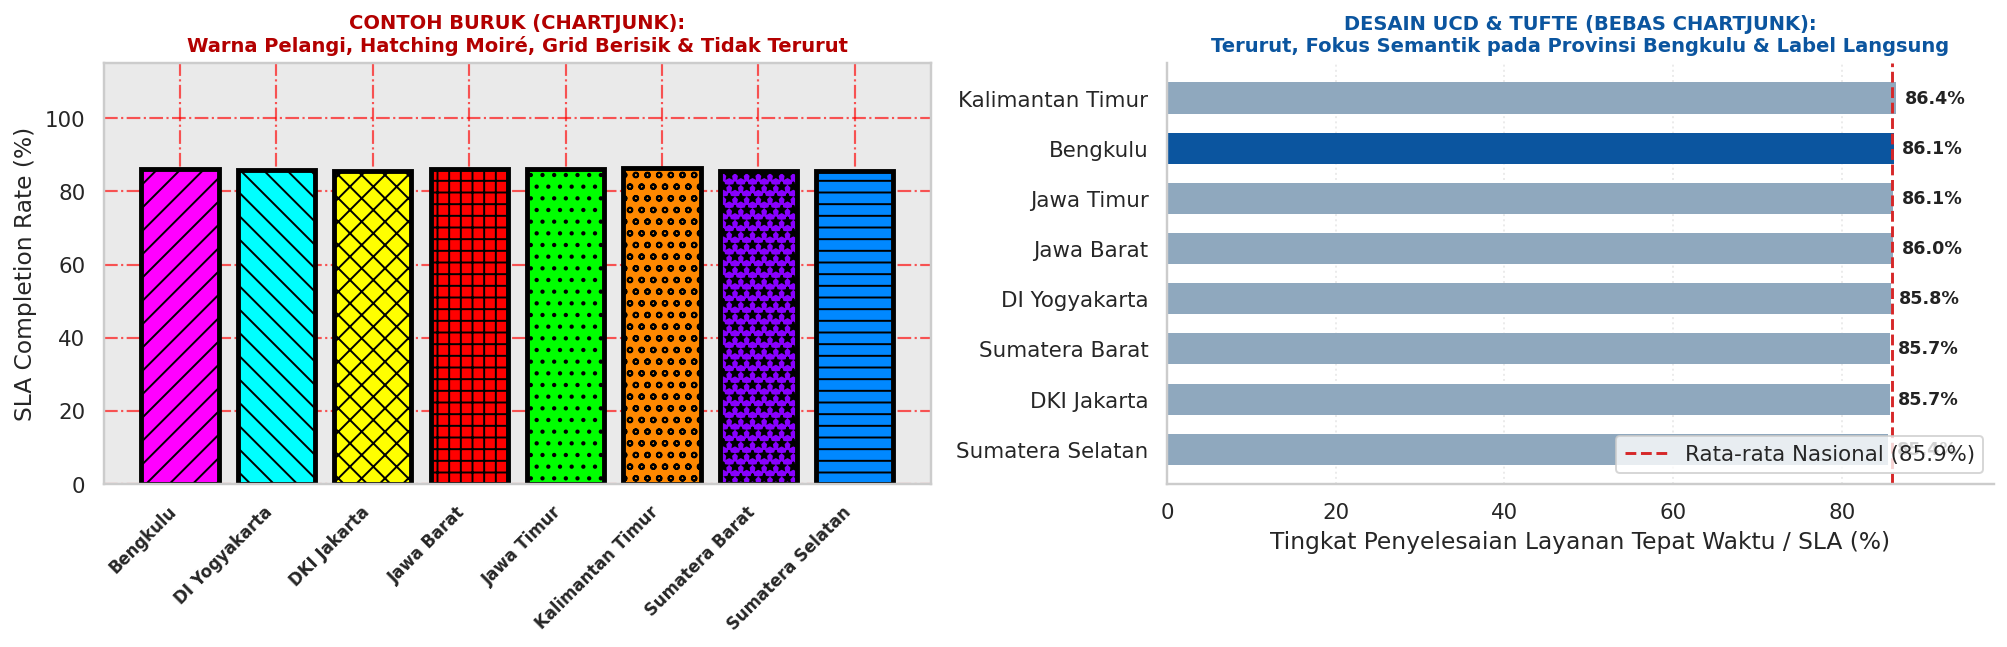

In [3]:
prov_sla = df_imk[df_imk["ui_design_version"] == "UI_Baru_UCD_Clean"].groupby("provinsi")["sla_completion_rate_pct"].mean().round(2)

fig, axes = plt.subplots(1, 2, figsize=(14.5, 4.8))

rainbow_colors = ["#ff00ff", "#00ffff", "#ffff00", "#ff0000", "#00ff00", "#ff8800", "#8800ff", "#0088ff"]
hatches = ["//", "\\\\", "xx", "++", "..", "oo", "**", "--"]
bars_bad = axes[0].bar(prov_sla.index, prov_sla.values, color=rainbow_colors, edgecolor="black", linewidth=2.5)
for bar, h in zip(bars_bad, hatches):
    bar.set_hatch(h)
axes[0].set_facecolor("#eaeaea")
axes[0].grid(True, which="both", color="red", linestyle="-.", linewidth=1.1, alpha=0.65)
axes[0].set_xticklabels(prov_sla.index, rotation=45, ha="right", fontsize=8.5, fontweight="bold")
axes[0].set_ylim(0, 115)
axes[0].set_title("CONTOH BURUK (CHARTJUNK):\nWarna Pelangi, Hatching Moiré, Grid Berisik & Tidak Terurut", fontsize=10, fontweight="bold", color="#b30000")
axes[0].set_ylabel("SLA Completion Rate (%)")

prov_sorted = prov_sla.sort_values(ascending=True)
nat_mean = prov_sorted.mean()
clean_colors = ["#0b559f" if p == "Bengkulu" else "#8fa8be" for p in prov_sorted.index]

bars_good = axes[1].barh(prov_sorted.index, prov_sorted.values, color=clean_colors, height=0.62, edgecolor="none")
axes[1].axvline(nat_mean, color="#d62728", linestyle="--", linewidth=1.5, label=f"Rata-rata Nasional ({nat_mean:.1f}%)")
axes[1].spines["top"].set_visible(False)
axes[1].spines["right"].set_visible(False)
axes[1].spines["left"].set_color("#cccccc")
axes[1].spines["bottom"].set_color("#cccccc")
axes[1].grid(axis="x", linestyle=":", alpha=0.4)
axes[1].grid(axis="y", visible=False)
axes[1].set_xlim(0, 98)

for bar in bars_good:
    val = bar.get_width()
    axes[1].text(val + 1.0, bar.get_y() + bar.get_height()/2, f"{val:.1f}%", va="center", ha="left", fontsize=9, fontweight="bold", color="#222222")

axes[1].set_title("DESAIN UCD & TUFTE (BEBAS CHARTJUNK):\nTerurut, Fokus Semantik pada Provinsi Bengkulu & Label Langsung", fontsize=10, fontweight="bold", color="#0b559f")
axes[1].set_xlabel("Tingkat Penyelesaian Layanan Tepat Waktu / SLA (%)")
axes[1].legend(loc="lower right", frameon=True)

plt.tight_layout()
plt.show()

### Tahap 2: Implementasi Arsitektur Dasbor *Shneiderman's Mantra* (Overview, Filter, Details-on-Demand)
Kita mengimplementasikan fungsi dasbor interaktif tiga tingkat yang menyajikan:
1. **Overview First:** Ringkasan KPI Makro & tren kuartalan.
2. **Zoom & Filter:** Penyaringan terfokus untuk wilayah **Bengkulu** dan perbandingan antar-kategori layanan publik.
3. **Details-on-Demand:** Tabel inspeksi terperinci untuk sesi layanan yang membutuhkan tindak lanjut perbaikan karena beban kognitif tinggi atau waktu pemahaman lambat.

 DASBOR EKSEKUTIF UCD | FILTER PROVINSI: BENGKULU | MODE: UI_Baru_UCD_Clean
[1. OVERVIEW KPI] Total Warga Terlayani : 116,745 warga (66 sesi)
                  Skor Usability (SUS)  : 84.51 / 100 (Standar Baik >= 68.0)
                  Beban Kognitif (TLX)  : 30.60 / 100 (Semakin Rendah Semakin Baik)
                  Time-to-Insight       : 17.52 detik

[2. ZOOM & FILTER: KINERJA PER KATEGORI LAYANAN DI PROVINSI TERPILIH]
                              Sesi  SUS_Rata2  Waktu_Insight_Detik  Error_Rate_Pct  SLA_Pct
kategori_layanan                                                                           
Perizinan_UMKM_Digital          16      83.42                16.42            2.44    87.45
Peringatan_Dini_Bencana         16      84.96                19.62            3.15    86.51
Layanan_Kesehatan_Terpadu       18      85.55                17.42            3.10    85.57
Transparansi_Anggaran_Publik    16      83.98                16.62            2.37    85.01

[3. DETAILS-ON-DEMA

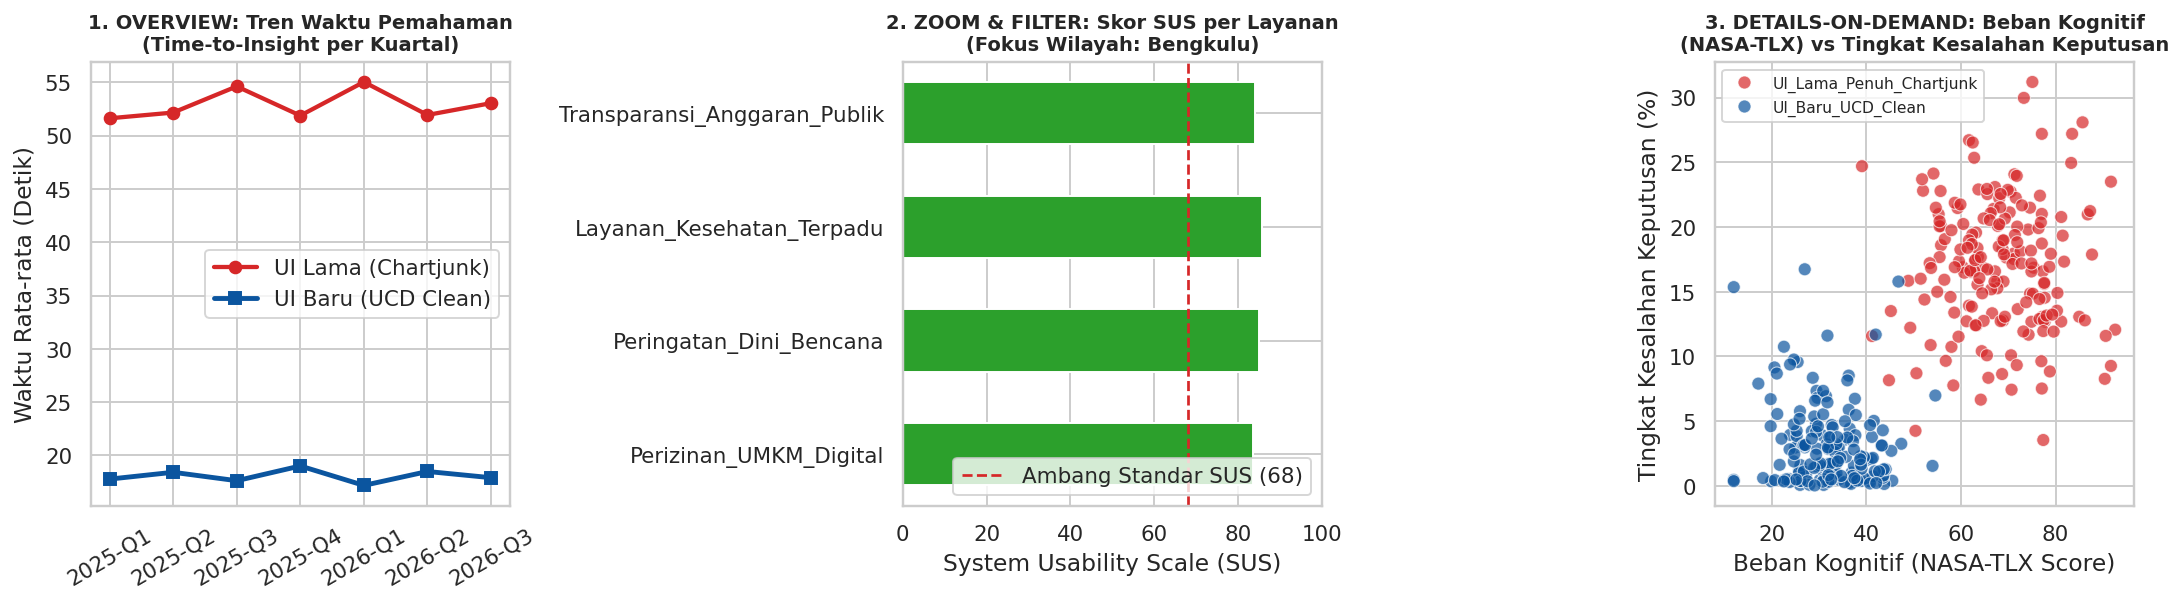

In [5]:
def run_interactive_ucd_dashboard(df, filter_provinsi="Bengkulu", filter_ui="UI_Baru_UCD_Clean"):
    df_ui = df[df["ui_design_version"] == filter_ui]
    df_filtered = df_ui[df_ui["provinsi"] == filter_provinsi]
    
    print(f"==============================================================================")
    print(f" DASBOR EKSEKUTIF UCD | FILTER PROVINSI: {filter_provinsi.upper()} | MODE: {filter_ui}")
    print(f"==============================================================================")
    print(f"[1. OVERVIEW KPI] Total Warga Terlayani : {df_filtered['active_citizens_served'].sum():,d} warga ({len(df_filtered)} sesi)")
    print(f"                  Skor Usability (SUS)  : {df_filtered['sus_usability_score'].mean():.2f} / 100 (Standar Baik >= 68.0)")
    print(f"                  Beban Kognitif (TLX)  : {df_filtered['nasa_tlx_cognitive_load'].mean():.2f} / 100 (Semakin Rendah Semakin Baik)")
    print(f"                  Time-to-Insight       : {df_filtered['time_to_insight_sec'].mean():.2f} detik")
    
    by_service = df_filtered.groupby("kategori_layanan").agg(
        Sesi=("session_id", "count"),
        SUS_Rata2=("sus_usability_score", "mean"),
        Waktu_Insight_Detik=("time_to_insight_sec", "mean"),
        Error_Rate_Pct=("decision_error_pct", "mean"),
        SLA_Pct=("sla_completion_rate_pct", "mean")
    ).round(2).sort_values("SLA_Pct", ascending=False)
    print("\n[2. ZOOM & FILTER: KINERJA PER KATEGORI LAYANAN DI PROVINSI TERPILIH]")
    print(by_service.to_string())
    
    anomalies = df_filtered.sort_values("time_to_insight_sec", ascending=False).head(5)[
        ["session_id", "kuartal", "kategori_layanan", "sus_usability_score", "nasa_tlx_cognitive_load", "time_to_insight_sec", "decision_error_pct"]
    ]
    print("\n[3. DETAILS-ON-DEMAND: TOP 5 SESI DENGAN WAKTU PEMAHAMAN TERLAMBAT (DRILL-DOWN)]")
    print(anomalies.to_string(index=False))
    
    fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.5))
    
    q_trend = df.groupby(["kuartal", "ui_design_version"])["time_to_insight_sec"].mean().unstack()
    axes[0].plot(q_trend.index, q_trend["UI_Lama_Penuh_Chartjunk"], marker="o", color="#d62728", lw=2.2, label="UI Lama (Chartjunk)")
    axes[0].plot(q_trend.index, q_trend["UI_Baru_UCD_Clean"], marker="s", color="#0b559f", lw=2.5, label="UI Baru (UCD Clean)")
    axes[0].set_title("1. OVERVIEW: Tren Waktu Pemahaman\n(Time-to-Insight per Kuartal)", fontsize=10, fontweight="bold")
    axes[0].set_ylabel("Waktu Rata-rata (Detik)")
    axes[0].tick_params(axis="x", rotation=30)
    axes[0].legend()
    
    axes[1].barh(by_service.index, by_service["SUS_Rata2"], color="#2ca02c", height=0.55)
    axes[1].axvline(68.0, color="#d62728", ls="--", lw=1.4, label="Ambang Standar SUS (68)")
    axes[1].set_xlim(0, 100)
    axes[1].set_title(f"2. ZOOM & FILTER: Skor SUS per Layanan\n(Fokus Wilayah: {filter_provinsi})", fontsize=10, fontweight="bold")
    axes[1].set_xlabel("System Usability Scale (SUS)")
    axes[1].legend(loc="lower right")
    
    sns.scatterplot(data=df.sample(350, random_state=42), x="nasa_tlx_cognitive_load", y="decision_error_pct",
                    hue="ui_design_version", palette={"UI_Lama_Penuh_Chartjunk": "#d62728", "UI_Baru_UCD_Clean": "#0b559f"},
                    alpha=0.7, s=45, ax=axes[2])
    axes[2].set_title("3. DETAILS-ON-DEMAND: Beban Kognitif\n(NASA-TLX) vs Tingkat Kesalahan Keputusan", fontsize=10, fontweight="bold")
    axes[2].set_xlabel("Beban Kognitif (NASA-TLX Score)")
    axes[2].set_ylabel("Tingkat Kesalahan Keputusan (%)")
    axes[2].legend(loc="upper left", fontsize=8)
    
    plt.tight_layout()
    plt.show()

run_interactive_ucd_dashboard(df_imk, filter_provinsi="Bengkulu", filter_ui="UI_Baru_UCD_Clean")